In [69]:
# multi class classification of FGL sources using tree categories
import numpy as np
import pandas as pd
from matplotlib import pyplot
from scipy.stats import binom
from astropy.io import fits
print(np.__version__)

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve
from sklearn.calibration import calibration_curve

import os
import sys
if '../lib/' not in sys.path:
    sys.path.append('../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil

1.21.5


In [70]:
if 1:
    import importlib
    importlib.reload(util);
    importlib.reload(putil);


In [71]:

def get_max_nodes_classes(dct, nsrc_df, max_depth=None):
    res = {}
    tree = list(dct.keys())
    max_nodes = []
    if max_depth is not None:
        max_nodes = [node for node in tree if len(node) == max_depth + 1]
    if len(max_nodes) == 0 or max_depth is None:
        max_nodes = [tree[i] for i in util.get_max_nodes(tree)]
    for node in max_nodes:
        cl = nsrc_df.loc[dct[node]['classes']].sort_values('n').index[-1]
        res[cl] = node
    return res

def get_class_diff(cl, max_cls_dict, nsrc_df, labels=None):
    
    clss = {}
    all_cls = []
    for i in range(2):
        if cl in max_cls_dict[i]:
            node = max_cls_dict[i][cl]
            clss[i] = roc_dict[i][node]['classes']
            all_cls.extend(roc_dict[i][node]['classes'])

    all_cls = list(set(all_cls))
    data = np.zeros((len(all_cls), 2), dtype=int)
    columns = labels
    if labels is None:
        columns = [0, 1]
    df = pd.DataFrame(index=all_cls, data=data, columns=columns)
    for i in range(2):
        if cl in max_cls_dict[i]:
            df[columns[i]].loc[clss[i]] = nsrc_df['n'].loc[clss[i]]
    df['sum'] = np.sum(df, axis=1)
    df.sort_values('sum', ascending=False, inplace=True)
    
    return df[columns]

In [72]:
plots_folder = '../plots/comparisons/'
paper_folder = '/Users/Dmitry/Work/Fermi/fermi_multiclass_papers/3_cov_shift_paper\
/cov_shift_paper_main/plots/'

save_plots = 0
save_png = 0
copy2tex = 0
max_depth = 4 #3 # None

cat_name = '4FGL_DR4'
config_folder = '../config/'
if cat_name == '4FGL_DR4':
    baseline_case = '4FGL_DR4_RF_RF'

if 1:
    case1 = '4FGL_DR4_RF_RF'
    #alg_descr1 = 'RF_depth15_GMM_nmin100'
    label1 = 'RF'
elif 0:
    alg_descr1 = 'RF_depth15_GMM_nmin100'
    label1 = 'RF'
elif 0:
    alg_descr1 = 'RF_weighted_training_weighted_test_depth15_GMM_nmin100'
    label1 = 'wRF'
elif 0:
    alg_descr1 = 'RF_weighted_test_depth15_GMM_nmin100'
    label1 = 'wtRF'
elif 0:
    alg_descr1 = 'RF_depth15_2class'
    label1 = '2-class'
elif 0:
    alg_descr1 = 'RF_weighted_test_depth15_2class'
    label1 = 'weighted test 2-class'
elif 0:
    alg_descr1 = 'NN_layers_20_10_GMM_nmin100'
    label1 = 'NN'
elif 0:
    alg_descr1 = 'NN_SK_weighted_test_layers_20_10_GMM_nmin100'
    label1 = 'wtNN_SK'
elif 0:
    alg_descr1 = 'NN_weighted_training_weighted_test_layers_20_10_GMM_nmin100'
    label1 = 'wNN'
elif 0:
    alg_descr1 = 'NN_weighted_test_layers_20_10_GMM_nmin100'
    label1 = 'wtNN'

if 1:
    case2 = '4FGL_DR4_RF_RF_w'
    label2 = 'wRF'    
if 0:
    alg_descr2 = 'RF_depth15_GMM_nmin15'
    label2 = 'GMM15'
elif 0:
    alg_descr2 = 'RF_depth15_RF_nmin100'
    label2 = 'RF'
elif 0:
    alg_descr2 = 'RF_weighted_training_weighted_test_depth15_GMM_nmin100'
    label2 = 'wRF'
elif 0:
    alg_descr2 = 'NN_layers_20_10_GMM_nmin100'
    label2 = 'NN_SK'
elif 0:
    alg_descr2 = 'NN_layers_20_10_GMM_nmin100'
    label2 = 'NN'
elif 0:
    alg_descr2 = 'NN_weighted_test_layers_20_10_GMM_nmin100'
    label2 = 'wtNN'
elif 0:
    alg_descr2 = 'NN_weighted_training_weighted_test_layers_20_10_GMM_nmin100'
    label2 = 'wNN'
elif 0:
    alg_descr2 = 'RF_resampled_training_resampled_test_depth15_GMM_nmin100'
    label2 = 'sRF'
elif 0:
    alg_descr2 = 'RF_resampled_training_weighted_test_depth15_GMM_nmin100'
    label2 = 'swRF'
elif 0:
    alg_descr2 = 'RF_weighted_test_depth15_GMM_nmin100'
    label2 = 'wtRF'
elif 0:
    alg_descr2 = 'RF_weighted_training_weighted_test_depth15_GMM_nmin100'
    label2 = 'wGMM'  
elif 0:
    alg_descr2 = 'RF_weighted_test_depth15_GMM_nmin100'
    label2 = 'wtGMM'  
elif 0:
    alg_descr2 = 'RF_weighted_training_weighted_test_depth15_2class'
    label2 = 'weighted 2-class'  
elif 0:
    alg_descr2 = 'RF_weighted_test_depth15_2class'
    label2 = 'weighted test 2-class'
elif 0:
    alg_descr2 = 'RF_resampled_training_resampled_test_depth15_2class'
    label2 = 's2cl'
    
alg_descr = []
for case in [case1, case2]:
    cdict = util.get_config_dict(cat_name=cat_name, 
                             baseline_case=baseline_case, 
                             case=case, 
                             folder=config_folder)

    alg_descr.append(util.get_alg_descr(cdict))

#alg_descr = [alg_descr1, alg_descr2]
labels = [label1, label2]
ns_tot = {lb:0 for lb in labels}
if alg_descr[0].find('2class') > -1 and alg_descr[1].find('2class') > -1:
    two_class = True
else:
    two_class = False
if two_class:
    titles = ['AGNs', 'Galactic']
    paper_folder += 'two_class/'
else:
    titles = None
    paper_folder += 'mclass_compare/'

if not os.path.isdir(plots_folder):
    os.mkdir(plots_folder)
if not os.path.isdir(paper_folder):
    os.mkdir(paper_folder)

roc_dict = {}
pr_dict = {}
cal_dict = {}
for i in range(2):
    folder = '../data_out/results_%s/' % alg_descr[i]
    roc_dict[i] = dio3.loaddict(folder + 'roc_dict.yaml')
    pr_dict[i] = dio3.loaddict(folder + 'pr_dict.yaml')
    cal_dict[i] = dio3.loaddict(folder + 'cal_dict.yaml')

nsrc_fn = '../data_out/nsrc_dict.yaml'
nsrc_dict = dio3.loaddict(nsrc_fn)
nsrc_df = util.nsrc_dict2df(nsrc_dict)

In [73]:
# compare ROCs
max_cls_dict = {}
for i in range(2):
    max_cls_dict[i] = get_max_nodes_classes(roc_dict[i], nsrc_df, max_depth=max_depth)
max_classes = [cl for cl in max_cls_dict[0].keys() if cl in max_cls_dict[1]]
max_classes.extend([cl for cl in max_cls_dict[0].keys() if cl not in max_cls_dict[1]])
max_classes.extend([cl for cl in max_cls_dict[1].keys() if cl not in max_cls_dict[0]])


In [74]:
max_cls_dict

{0: {'bcu': '00000',
  'msp': '00010',
  'psr': '00011',
  'fsrq': '00100',
  'bll': '01000',
  'rdg': '01100'},
 1: {'bcu': '00000',
  'msp': '00010',
  'psr': '00011',
  'fsrq': '00100',
  'bll': '01000',
  'rdg': '01100'}}

In [75]:
if 0:
    max_depth = 4
    tree = list(roc_dict[0].keys())
    max_nodes = [node for node in tree if len(node) == max_depth + 1]
    #max_nodes = [tree[i] for i in util.get_max_nodes(tree)]
    max_nodes

In [76]:
alg_descr

['4FGL_DR4_all_assoc_all_features_RF_nmin100_RF_depth15',
 '4FGL_DR4_all_assoc_all_features_RF_nmin100_RF_weighted_training_weighted_test_depth15']

In [77]:
two_class

False

In [78]:
max_classes

['bcu', 'msp', 'psr', 'fsrq', 'bll', 'rdg']

In [79]:
single_plot_pars = {}
if len(max_classes) < 3:
    ncols = 2
else:
    ncols = 3
nrows = int(np.ceil(1. * len(max_classes) / ncols))


if two_class:
    fig_height = 4   # height in inches
    fig_width = 10  # width in inches
    #all_plots_pars = {'axes.titlesize':18}
    all_plots_pars = {'bottom':0.15, 'left':0.1, 'right':0.97, 'axes.titlesize':18}
    fig_size =  [fig_width, fig_height]
    all_plots_pars['fig_size'] = fig_size
    all_plots_pars['font.size'] = 12
    all_plots_pars['legend.fontsize'] = 12
    
else:
    fig_height = 2.5 * nrows + 2   # height in inches
    fig_width = 3 * ncols + 2  # width in inches

    #all_plots_pars = {'axes.titlesize':18}
    all_plots_pars = {'bottom':0.1, 'left':0.08, 'right':0.97, 'axes.titlesize':18}
    fig_size =  [fig_width, fig_height]
    all_plots_pars['fig_size'] = fig_size
    all_plots_pars['font.size'] = 11
    all_plots_pars['legend.fontsize'] = 11
putil.setup_figure_pars(pars_dict=all_plots_pars)
colors = pyplot.rcParams['axes.prop_cycle'].by_key()['color']
print(ncols, nrows)
#putil.setup_figure_pars(pars_dict=single_plot_pars)

3 2


In [80]:
ncols

3

In [81]:
max_cls_dict

{0: {'bcu': '00000',
  'msp': '00010',
  'psr': '00011',
  'fsrq': '00100',
  'bll': '01000',
  'rdg': '01100'},
 1: {'bcu': '00000',
  'msp': '00010',
  'psr': '00011',
  'fsrq': '00100',
  'bll': '01000',
  'rdg': '01100'}}

0 msp
1 msp


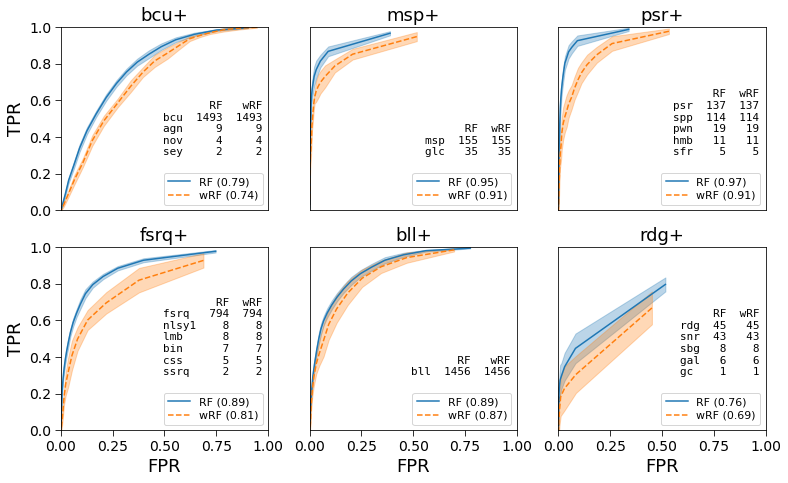

In [82]:
lss = ['-', '--']
check_class = 'msp'

auc_dict = {lb:1. for lb in labels}
pyplot.figure()
for ind, cl in enumerate(max_classes[:]):
    cind = -1
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    #ax = pyplot.subplot(111)
    #print(cl)
    df = get_class_diff(cl, max_cls_dict, nsrc_df, labels=labels)
    #print(df)
    #print()
    for i in range(2):
        cind += 1
        if cl in max_cls_dict[i]:
            node = max_cls_dict[i][cl]
            fpr = np.array(roc_dict[i][node][len(node) - 2]['FPR'])
            tpr = np.array(roc_dict[i][node][len(node) - 2]['TPR'])
            tpr_std = np.array(roc_dict[i][node][len(node) - 2]['TPR_STD'])
            auc = roc_dict[i][node][len(node) - 2]['AUC']
            auc_dict[labels[i]] *= auc
            cls = roc_dict[i][node]['classes']
            ns = int(np.sum(nsrc_df.loc[cls]).iloc[0])
            ns_tot[labels[i]] += ns
            if cl == check_class:# and i == 1:
                print(i, cl)
                if i == 0:
                    cdict = {}
                cdict[i] = {}
                #print('FPR', fpr)
                #print('TPR', tpr)
                cdict[i]['FPR'] = fpr
                cdict[i]['TPR'] = tpr
                cdict[i]['auc'] = auc
                #print(roc_dict[i][node][len(node) - 2].keys())

            #print(roc_dict[i][node])
            #print(nsrc_df.loc[cls].sort_values('n', ascending=False))
            label = labels[i] + ' (%.2f)' % auc
            pyplot.plot(fpr, tpr, c=colors[cind], ls=lss[i], label=label)
            pyplot.fill_between(fpr, tpr - tpr_std, tpr + tpr_std, 
                                color=colors[cind], alpha=0.3)
    
    if 1:
        pyplot.legend(loc='lower right', labelspacing=0.3, #fontsize=10
                     )
    elif ind > 2:
        pyplot.legend(loc=(0.5, 0.6), #fontsize=10
                     )
    elif ind == 2:
        pyplot.legend(loc=(0.5, 0.75), #fontsize=10
                     )
    else:
        pyplot.legend(loc=(0.5, 0.7), #fontsize=10
                     )
        
    #pyplot.title('%s-like' % cl)
    if titles is None:
        pyplot.title(cl + '+')
    else:
        pyplot.title(titles[ind])
    pyplot.xlabel('FPR')
    pyplot.ylabel('TPR')
    if ind < ncols * (nrows - 1):
        ax.axes.xaxis.set_visible(False)
    if ind % 3 != 0:
        ax.axes.yaxis.set_visible(False)

    #txt = df.to_csv().replace(',','\t').expandtabs() # str(df)
    if not two_class and max_depth > 1:
        txt = str(df)
        ax.text(0.97, 0.29, txt, #fontsize=10, 
                fontfamily='monospace', 
                horizontalalignment='right', verticalalignment='bottom')
    pyplot.xlim(0, 1)
    pyplot.ylim(0, 1)

if save_plots:
    if two_class:
        fn = '%s/ROC_comparison_%s_%s.pdf' % (plots_folder, alg_descr1, alg_descr2)
    else:
        fn = '%s/ROC_comparison_%s_%s_depth%i.pdf' % (plots_folder, alg_descr1, alg_descr2, max_depth)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        print('save figure to file: %s' % (fn_png))
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, paper_folder)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



In [83]:
def auc_loc(fpr, tpr):
    fpr_ = list(np.sort(fpr))
    fpr_.append(1.)
    fpr_ = np.array(fpr_)
    dx = fpr_[1:] - fpr_[:-1]
    tpr_ = list(np.sort(tpr))
    tpr_.append(1.)
    tpr_ = np.array(tpr_)
    ys = (tpr_[1:] + tpr_[:-1]) / 2.
    return np.sum(ys * dx)
    

In [84]:
cdict

{0: {'FPR': array([3.87765355e-01, 8.96213283e-02, 5.19031102e-02, 3.19011543e-02,
         2.17390721e-02, 1.62180911e-02, 1.23081605e-02, 9.30849728e-03,
         7.53539599e-03, 6.29456242e-03, 6.06395140e-03, 4.06307074e-03,
         3.57630671e-03, 2.86447494e-03, 1.91293162e-03, 1.41439754e-03,
         9.48554413e-04, 3.96211180e-04, 2.51710427e-04, 8.35041353e-05]),
  'TPR': array([0.96632973, 0.86772345, 0.81458503, 0.76811116, 0.73023174,
         0.68982622, 0.65986913, 0.6252971 , 0.590775  , 0.54307641,
         0.50626939, 0.47539729, 0.44922589, 0.40373216, 0.36149874,
         0.28116198, 0.23570636, 0.15563918, 0.09618365, 0.03415209]),
  'auc': 0.9548683437248489},
 1: {'FPR': array([5.16962595e-01, 2.07209441e-01, 1.21583403e-01, 7.46777269e-02,
         5.26129736e-02, 4.06901088e-02, 3.11397396e-02, 2.39806298e-02,
         1.99715336e-02, 1.57919639e-02, 1.27791345e-02, 1.08900907e-02,
         9.61395261e-03, 8.14765720e-03, 6.54766817e-03, 3.98616611e-03,
      

In [85]:
for i in range(2):
    auc_test = auc_loc(cdict[i]['FPR'], cdict[i]['TPR'])
    print(i, auc_test, cdict[i]['auc'])

0 0.9431834535134158 0.9548683437248489
1 0.9005253197581529 0.9106500658263329


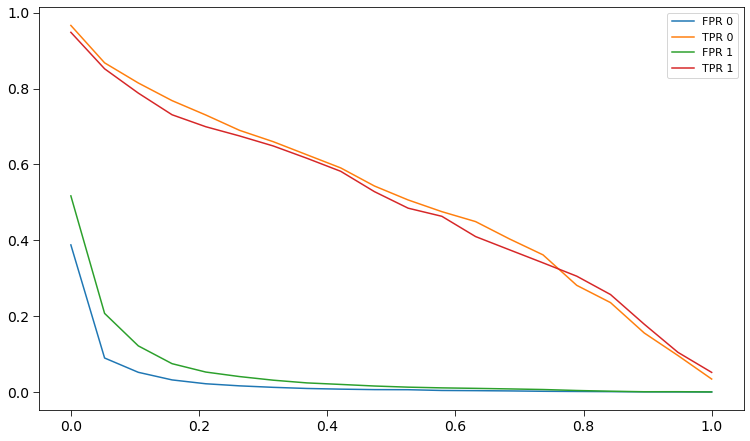

In [86]:
if 1:
    pyplot.figure()
    for i in range(2):
        nbins = len(cdict[i]['FPR'])
        pyplot.plot(np.linspace(0, 1, nbins), cdict[i]['FPR'], label='FPR %i' %i)
        pyplot.plot(np.linspace(0, 1, nbins), cdict[i]['TPR'], label='TPR %i' %i)
    pyplot.legend()

In [87]:
#cdict

In [88]:
for lb, auc in auc_dict.items():
    print('%s prod AUC = %.4f' % (lb, auc))

RF prod AUC = 0.4411
wRF prod AUC = 0.2955


RF bcu precision at 0.50 thres: 0.60
wRF bcu precision at 0.50 thres: 0.64
RF bcu recall at 0.50 thres: 0.62
wRF bcu recall at 0.50 thres: 0.75

RF msp precision at 0.50 thres: 0.81
Precision [0.22739439 0.37016583 0.48032965 0.57762351 0.64827113 0.69427706
 0.74086434 0.78240402 0.80100036 0.82100503 0.83343072 0.85349307
 0.85476291 0.86186971 0.87541947 0.91354643 0.94213854 0.97177283
 0.96872215 0.98575279]
wRF msp precision at 0.50 thres: 0.82
RF msp recall at 0.50 thres: 0.54
Recall (TPR) [0.93859235 0.85210614 0.78763304 0.73105087 0.69929807 0.67488721
 0.64845975 0.6161114  0.58192558 0.52856382 0.48459101 0.46317115
 0.4097316  0.3742944  0.34163812 0.30546221 0.2569635  0.17538842
 0.11297845 0.05829961]
wRF msp recall at 0.50 thres: 0.53

RF psr precision at 0.50 thres: 0.75
wRF psr precision at 0.50 thres: 0.70
RF psr recall at 0.50 thres: 0.66
wRF psr recall at 0.50 thres: 0.54

RF fsrq precision at 0.50 thres: 0.73
wRF fsrq precision at 0.50 thres: 0.54
RF fsrq recall 

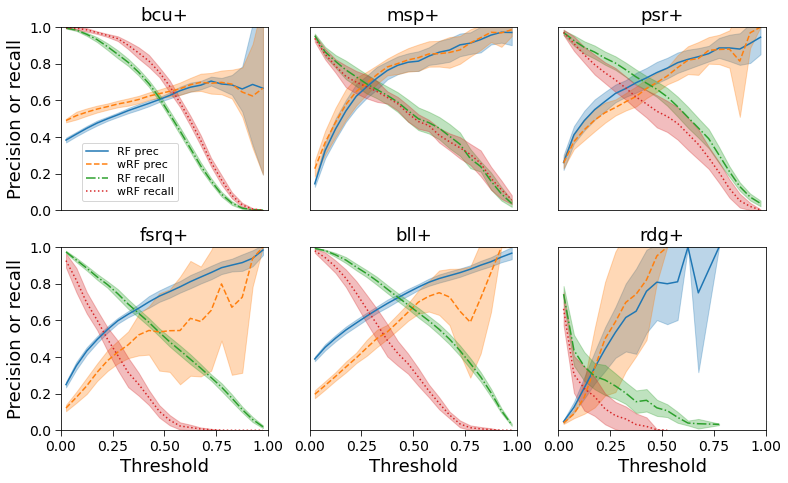

In [89]:
lsp = lss
lsr = ['-.', ':']
#thres_out = [0.25, 0.5, 0.75] # None
thres_out = [0.5]
#thres_out = None


pyplot.figure()
for ind, cl in enumerate(max_classes[:]):
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    cind = -1
    for i in range(2):
        cind += 1
        if cl in max_cls_dict[i]:
            node = max_cls_dict[i][cl]
            thres_prec = np.array(pr_dict[i][node][len(node) - 2]['thres_prec'])
            prec = np.array(pr_dict[i][node][len(node) - 2]['prec'])
            prec_std = np.array(pr_dict[i][node][len(node) - 2]['prec_std'])
            
            if cl == check_class and i == 1:
                print('Precision', prec)

            #cls = roc_dict[i][node]['classes']
            #ns = int(np.sum(nsrc_df.loc[cls]))
            #ns_tot[labels[i]] += ns
            #label = labels[i] + ' (%i)' % ns
            label = labels[i]
            pyplot.plot(thres_prec, prec, ls=lsp[i], color=colors[cind], 
                        label=label + ' prec')
            pyplot.fill_between(thres_prec, prec - prec_std, prec + prec_std, 
                                color=colors[cind], alpha=0.3)
            
            if thres_out is not None:
                for thres in thres_out:
                    ii = np.argmin(np.abs(thres_prec - thres))
                    print('%s %s precision at %.2f thres: %.2f' % (label, cl, thres, prec[ii]))
        
    for i in range(2):
        cind += 1
        if cl in max_cls_dict[i]:
            node = max_cls_dict[i][cl]
            thres_recall = np.array(pr_dict[i][node][len(node) - 2]['thres_recall'])
            recall = np.array(pr_dict[i][node][len(node) - 2]['recall'])
            recall_std = np.array(pr_dict[i][node][len(node) - 2]['recall_std'])
            
            if cl == check_class and i == 1:
                print('Recall (TPR)', recall)

            label = labels[i]
            pyplot.plot(thres_recall, recall, ls=lsr[i], color=colors[cind], 
                        label=label + ' recall')
            pyplot.fill_between(thres_recall, recall - recall_std, recall + recall_std, 
                                color=colors[cind], alpha=0.3)
            if thres_out is not None:
                for thres in thres_out:
                    ii = np.argmin(np.abs(thres_prec - thres))
                    print('%s %s recall at %.2f thres: %.2f' % (label, cl, thres, recall[ii]))

    if thres_out is not None:
        print()
        
    if ind < ncols * (nrows - 1):
        ax.axes.xaxis.set_visible(False)
    if ind % 3 != 0:
        ax.axes.yaxis.set_visible(False)
    if ind == 0:
        pyplot.legend(loc=(0.1, 0.05), labelspacing=0.3, #fontsize=10
                     )
    #pyplot.title(cl)
    if titles is None:
        pyplot.title(cl + '+')
    else:
        pyplot.title(titles[ind])
    pyplot.xlabel('Threshold')
    pyplot.ylabel('Precision or recall')
    pyplot.xlim(0, 1)
    pyplot.ylim(0, 1)
if save_plots:
    if two_class:
        fn = '%s/PR_comparison_%s_%s.pdf' % (plots_folder, alg_descr1, alg_descr2)
    else:
        fn = '%s/PR_comparison_%s_%s_depth%i.pdf' % (plots_folder, alg_descr1, alg_descr2, max_depth)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        print('save figure to file: %s' % (fn_png))
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, paper_folder)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



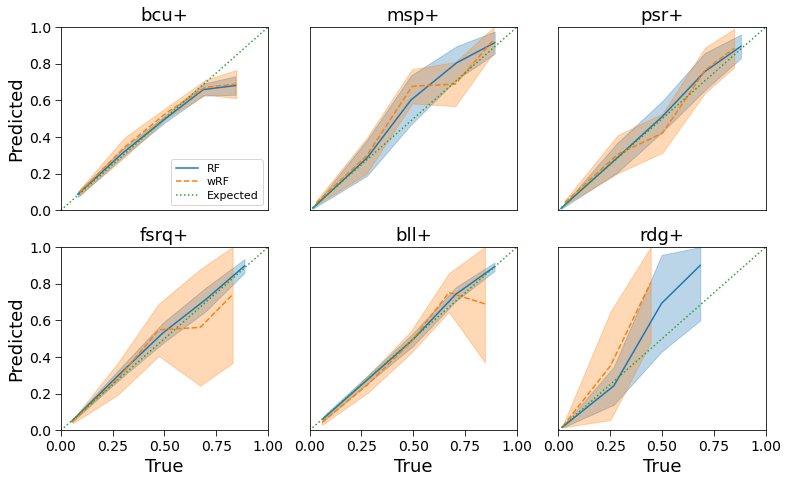

In [90]:

pyplot.figure()
for ind, cl in enumerate(max_classes[:]):
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    cind = -1
    for i in range(2):
        cind += 1
        if cl in max_cls_dict[i]:
            node = max_cls_dict[i][cl]
            predicted = np.array(cal_dict[i][node][len(node) - 2]['predicted'])
            true = np.array(cal_dict[i][node][len(node) - 2]['true'])
            true_min = np.array(cal_dict[i][node][len(node) - 2]['true_min'])
            true_max = np.array(cal_dict[i][node][len(node) - 2]['true_max'])
            
            label = labels[i]
            pyplot.plot(predicted, true, ls=lsp[i], color=colors[cind], 
                        label=label)
            pyplot.fill_between(predicted, true_min, true_max, 
                                color=colors[cind], alpha=0.3)
    cind += 1
    pyplot.plot([0,1], [0,1], ls=':', color=colors[cind], label='Expected')
    
    if ind < ncols * (nrows - 1):
        ax.axes.xaxis.set_visible(False)
    if ind % 3 != 0:
        ax.axes.yaxis.set_visible(False)
    if ind == 0:
        pyplot.legend(loc='lower right', labelspacing=0.3, #fontsize=10
                     )
    #pyplot.title(cl)
    if titles is None:
        pyplot.title(cl + '+')
    else:
        pyplot.title(titles[ind])
    pyplot.xlabel('True')
    pyplot.ylabel('Predicted')
    pyplot.xlim(0, 1)
    pyplot.ylim(0, 1)
if save_plots:
    if two_class:
        fn = '%s/cal_comparison_%s_%s.pdf' % (plots_folder, alg_descr1, alg_descr2)
    else:
        fn = '%s/cal_comparison_%s_%s_depth%i.pdf' % (plots_folder, alg_descr1, alg_descr2, max_depth)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        print('save figure to file: %s' % (fn_png))
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, paper_folder)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)

